# EDA Анализ курсов валют к бангладешской таке (BDT)
**Гипотеза:** Курсообразование бангладешской таки (BDT) носит искусственный нерыночный характер, при котором Центральный банк жестко фиксирует курс, что в итоге приводит к исчерпанию резервов, кризисам ликвидности и шоковым девальвациям.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

## 1. Загрузка и подготовка данных

In [2]:
df = pd.read_csv('bb.csv')
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df.head()

,date,base,quote,type,value,year,month
0,2010-11-01,AUD,BDT,buy,69.3001,2010,11
1,2010-11-01,AUD,BDT,sell,69.3355,2010,11
2,2010-11-01,CAD,BDT,buy,69.1984,2010,11
3,2010-11-01,CAD,BDT,sell,69.2119,2010,11
4,2010-11-01,EUR,BDT,buy,98.4003,2010,11


## 2. Линейная динамика курсов
Базовый макроэкономический обзор. Демонстрирует "эпохи" жизни валюты: долгий период искусственного удержания доллара и последующий резкий обвал национальной валюты, начавшийся в 2022 году.

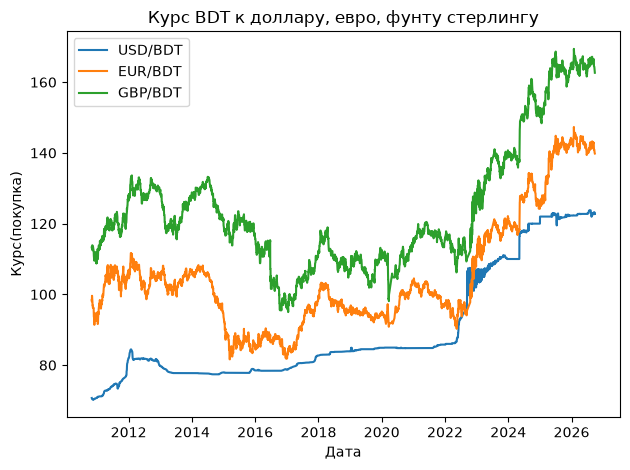

In [3]:
plt.figure()
for curr in ['USD', 'EUR', 'GBP']:
    subset = df[(df['base'] == curr) & (df['type'] == 'buy')].sort_values('date')
    plt.plot(subset['date'], subset['value'], label=f'{curr}/BDT')
plt.title('Курс BDT к доллару, евро, фунту стерлингу')
plt.xlabel('Дата')
plt.ylabel('Курс(покупка)')
plt.legend()
plt.tight_layout()
plt.show()

## 3. Динамика спреда
График показывает "здоровье" и ликвидность банковского сектора. Резкие фиолетовые спайки визуализируют моменты жесткого дефицита и паники, когда банки сильно завышали цену продажи относительно цены покупки.

C:\Users\maxma\AppData\Local\Temp\ipykernel_15348\2154999800.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


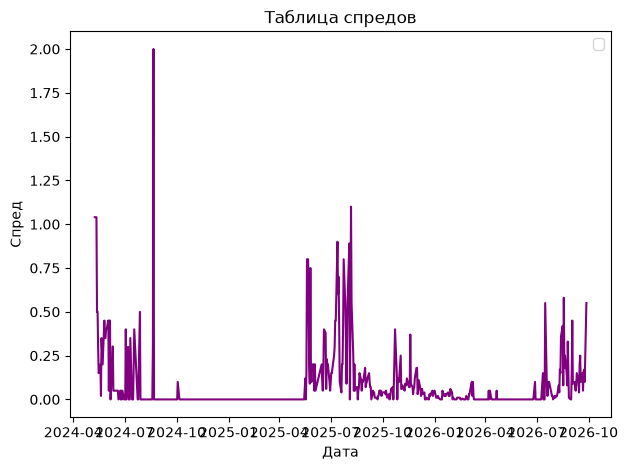

In [4]:
usd_df = df[df['base'] == 'USD'].pivot_table(index='date', columns='type', values='value').dropna()
usd_df['spread'] = usd_df['sell'] - usd_df['buy']
plt.figure()
plt.title('Таблица спредов')
plt.plot(usd_df.index, usd_df['spread'], color='purple')
plt.xlabel('Дата')
plt.ylabel('Спред')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Распределение курса покупки USD по годам (Boxplot)
Показывает беспрецедентный рост дисперсии. Сплюснутые в линию "ящики" до 2021 года визуализируют успешный контроль Центробанка над волатильностью. Огромные растянутые ящики с 2022 года иллюстрируют высокую нестабильность.

C:\Users\maxma\AppData\Local\Temp\ipykernel_15348\3336895585.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


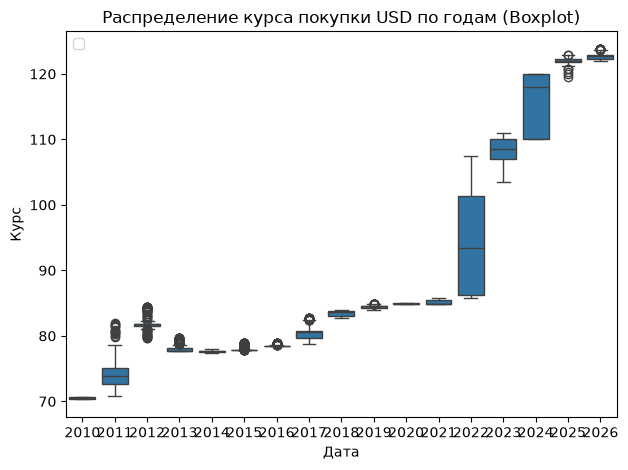

In [5]:
plt.figure()
sns.boxplot(x=df[df['base']=='USD']['year'], y=df[(df['base']=='USD') & (df['type']=='buy')]['value'])
plt.title('Распределение курса покупки USD по годам (Boxplot)')
plt.xlabel('Дата')
plt.ylabel('Курс')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Матрица корреляций
Коэффициенты > 0.88 между USD, EUR и GBP доказывают системный характер проблемы. Бангладешская така обесценивалась синхронно ко всей корзине мировых резервных валют.

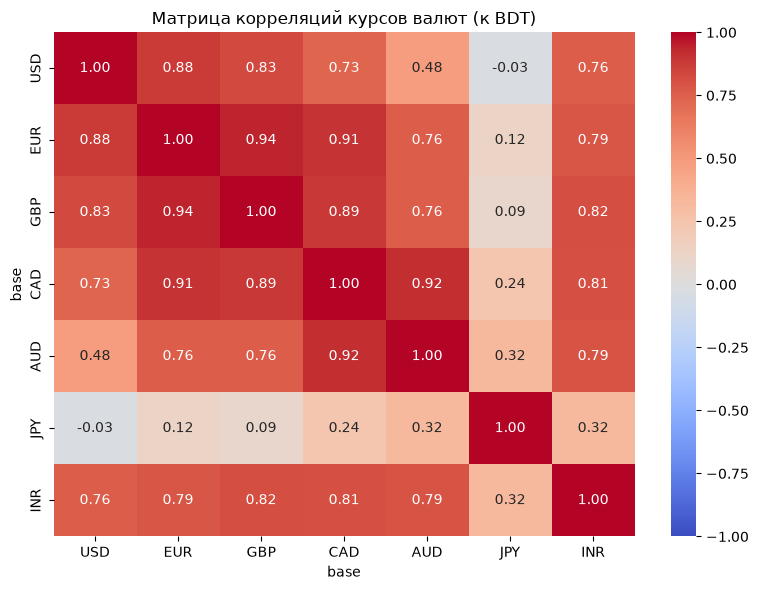

In [6]:
pivot_buy = df[df['type'] == 'buy'].pivot_table(index='date', columns='base', values='value')
top_currencies = ['USD', 'EUR', 'GBP', 'CAD', 'AUD', 'JPY', 'INR']
corr_matrix = pivot_buy[top_currencies].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f')
plt.title('Матрица корреляций курсов валют (к BDT)')
plt.tight_layout()
plt.show()

## 6. Статистическое подтверждение смены режима (T-test)
Практически нулевое значение T-теста математически гарантирует, что между 2021 и 2022 годами произошел необратимый структурный сдвиг.

In [7]:
usd_2021 = df[(df['base'] == 'USD') & (df['date'].dt.year == 2021)]['value']
usd_2022 = df[(df['base'] == 'USD') & (df['date'].dt.year == 2022)]['value']
t_stat, p_value = stats.ttest_ind(usd_2021, usd_2022)
print(f"P-value: {p_value}")

P-value: 4.048767645719099e-107


## 7. Анализ формы распределения (Асимметрия и Эксцесс)
Значение эксцесса ~76 указывает на экстремально «толстые хвосты» — курс стоит на месте месяцами, после чего происходят внезапные ценовые шоки огромной амплитуды. Положительная асимметрия доказывает, что редкие сильные скачки курса происходят строго в сторону удорожания доллара.

In [8]:
usd_returns = df[(df['base'] == 'USD') & (df['type'] == 'buy')]['value'].pct_change().dropna()
skewness = stats.skew(usd_returns)
kurtosis = stats.kurtosis(usd_returns, fisher=False) # fisher=False значит эталон = 3
print(f"Асимметрия (Skewness): {skewness}")
print(f"Эксцесс (Kurtosis): {kurtosis}")

Асимметрия (Skewness): 1.5122956758206134
Эксцесс (Kurtosis): 76.2024117889833


## 8. Гистограмма распределения с эталоном Гаусса
Визуализирует рассчитанный эксцесс. Огромный синий шпиль строго на нулевой отметке означает, что в большинстве торговых дней курс менялся ровно на 0.00%. Гладкий колокол нормального распределения (черная линия) на этом рынке не работает.

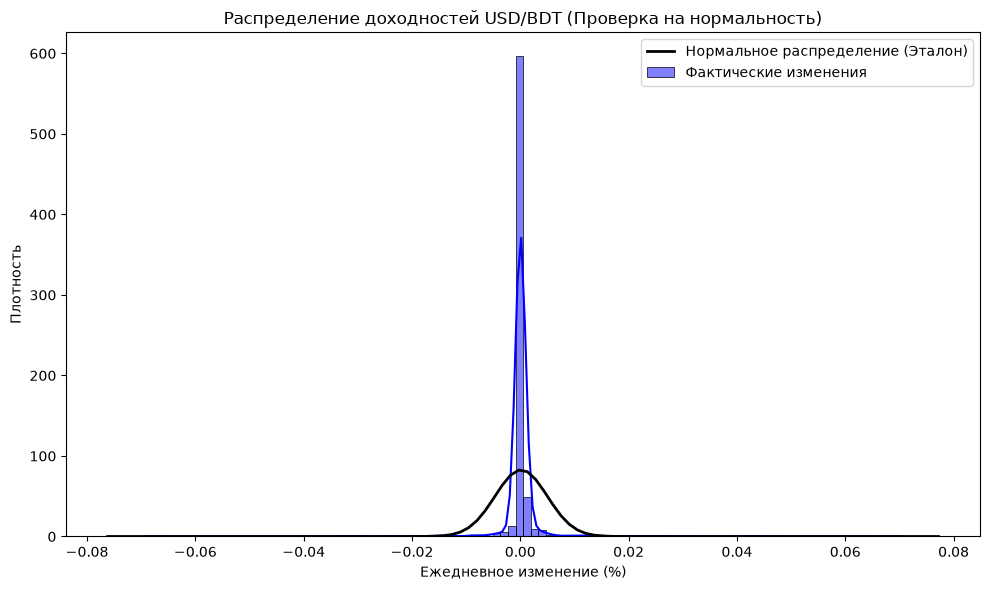

In [9]:
plt.figure(figsize=(10, 6))
sns.histplot(usd_returns, bins=100, kde=True, stat="density", color='blue', alpha=0.5, label='Фактические изменения')

xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 100)
p = stats.norm.pdf(x, np.mean(usd_returns), np.std(usd_returns))
plt.plot(x, p, 'k', linewidth=2, label='Нормальное распределение (Эталон)')

plt.title('Распределение доходностей USD/BDT (Проверка на нормальность)')
plt.xlabel('Ежедневное изменение (%)')
plt.ylabel('Плотность')
plt.legend()
plt.tight_layout()
plt.show()